## 07 · A Real Village

Notebooks 01–06 used a simulated village whose solar output and demand came from formulas. From here on, the grid runs on a year of real hourly data from Agoro, a mini-grid village in northern Uganda: measured household and business demand, and solar output for the same district from PVGIS.

The system is resized for the village using the design ratios of a commercial solar microgrid in Nigeria (1.52 kWp of solar per kW of peak load, 1.5 kWh of battery per kWp): 36 kWp of solar, a 54 kWh lithium battery and a 25 kW diesel generator.

*Data: Agoro load and Lamwo solar series from the SEL-Columbia mini-grid generation system design repository (used locally pending the authors' permission).*

In [1]:
# Load the real Agoro data and build the environment and rulebook with the Agoro system configuration
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from minigrid_mdp.real_data import load_pvgis_per_kwp, load_hourly_load_kw
from minigrid_mdp.env.data_env import DataDrivenEnv
from minigrid_mdp.agents import RuleBasedAgent
from minigrid_mdp.metrics import run_days, summarise, compare
from minigrid_mdp.plotting import plot_day

DATA_DIR = Path("..") / "data" / "raw" / "uganda_agoro"
AGORO_CONFIG = Path("..") / "minigrid_mdp" / "config" / "system_params_agoro.yaml"

pv_per_kwp = load_pvgis_per_kwp(DATA_DIR / "lamwo_solar_2019.csv")
load_kw = load_hourly_load_kw(DATA_DIR / "agoro_fixed_loads.csv")

env = DataDrivenEnv(pv_per_kwp, load_kw, config_path=AGORO_CONFIG)
rulebook = RuleBasedAgent(env.action_space, config_path=AGORO_CONFIG)

print(f"Solar {env.pv_cfg['rated_power_kw']} kWp | Battery {env.bat_cfg['capacity_kwh']} kWh | "
      f"Diesel {env.die_cfg['rated_power_kw']} kW | Rulebook sun threshold {rulebook.pv_negligible_kw:.1f} kW")

Solar 36.0 kWp | Battery 54.0 kWh | Diesel 25.0 kW | Rulebook sun threshold 3.6 kW


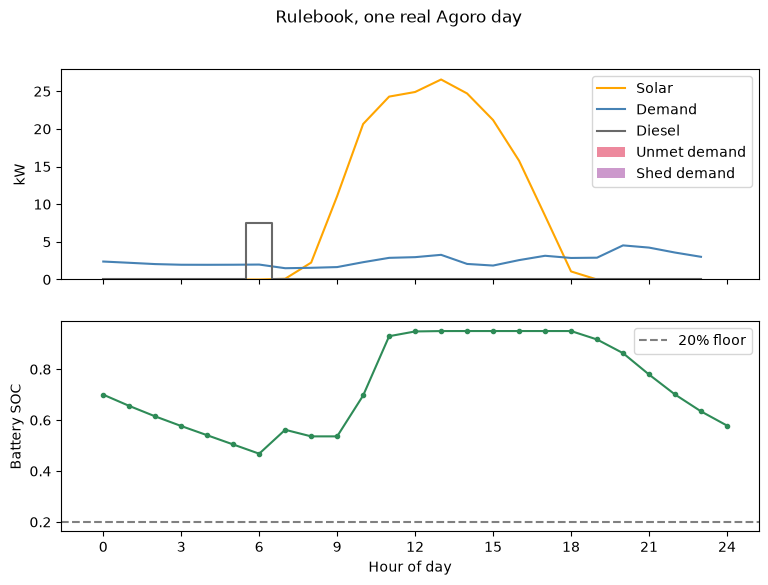

In [2]:
# Run the rulebook for one real day and plot it
day = run_days(env, rulebook, n_days=1)
plot_day(day, env.bat_cfg["initial_soc"], env.bat_cfg["min_soc"], title="Rulebook, one real Agoro day")
plt.show()

In [3]:
# Run the rulebook over 20 real days and summarise, including wasted solar per day
log = run_days(env, rulebook, n_days=20)
summary = summarise(log)
wasted = log.curtailed_kw.where(log.action != 4, 0.0).groupby(log.episode).sum()
summary = summary.assign(wasted_solar_kwh=wasted, demand_kwh=log.groupby("episode").load_kw.sum())
compare({"rulebook": summary})

rulebook       
                     mean    std
diesel_hours_pct    11.46   7.26
fuel_cost_usd        5.44   3.22
unmet_pct            0.00   0.00
end_soc              0.52   0.05
reward              -5.44   3.22
wasted_solar_kwh    73.27  50.56
demand_kwh         100.53  27.23

In [4]:
# Share of the 20 days on which diesel ran at each hour, and average fuel cost per hour
by_hour = log.groupby("hour").agg(diesel_share=("diesel_on", "mean"), fuel_usd=("rew_fuel", lambda x: -x.mean()))
by_hour[by_hour.diesel_share > 0].round(2)

,diesel_share,fuel_usd
hour,,
3,0.10,0.20
4,0.15,0.31
5,0.55,1.13
6,0.30,0.62
7,0.15,0.31
8,0.05,0.10
9,0.05,0.10
10,0.10,0.22
12,0.05,0.10


## A rulebook from real site practice

The original rulebook was written for the simulated village, and in Agoro it starts the generator whenever the battery dips below 50% after dark, often an hour or two before sunrise. Real operators work differently. At an EMONE site, the rule was: start the generator when the battery falls below 30%, charge it back to 50%, then switch it off. Solar serves the load whenever the sun is up.

We compare the two rulebooks on the same 20 real days.

In [5]:
# Compare the original rulebook and the EMONE-practice rulebook over the same 20 real days
from minigrid_mdp.agents.operator_rulebook import OperatorRulebook

def summarise_with_waste(log):
    wasted = log.curtailed_kw.where(log.action != 4, 0.0).groupby(log.episode).sum()
    return summarise(log).assign(wasted_solar_kwh=wasted)

operator = OperatorRulebook(env.action_space, config_path=AGORO_CONFIG)
operator_log = run_days(env, operator, n_days=20)

compare({
    "original_rulebook": summarise_with_waste(log),
    "operator_rulebook":    summarise_with_waste(operator_log),
})

original_rulebook        operator_rulebook       
                              mean    std              mean    std
diesel_hours_pct             11.46   7.26              3.54   4.93
fuel_cost_usd                 5.44   3.22              2.29   3.24
unmet_pct                     0.00   0.00              0.00   0.00
end_soc                       0.52   0.05              0.43   0.11
reward                       -5.44   3.22             -2.73   3.69
wasted_solar_kwh             73.27  50.56             67.11  46.59

In [6]:
# Run both rulebooks for 4 continuous weeks of real data; summarise days 2-7 of each week
from minigrid_mdp.metrics import run_weeks, steady_state_days

week_env = DataDrivenEnv(pv_per_kwp, load_kw, config_path=AGORO_CONFIG, days_per_episode=7)
week_operators = {
    "original_rulebook": RuleBasedAgent(week_env.action_space, config_path=AGORO_CONFIG),
    "operator_rulebook":    OperatorRulebook(week_env.action_space, config_path=AGORO_CONFIG),
}
compare({name: summarise_with_waste(steady_state_days(run_weeks(week_env, agent)))
         for name, agent in week_operators.items()})

original_rulebook        operator_rulebook       
                              mean    std              mean    std
diesel_hours_pct             13.37   6.61              8.85   4.65
fuel_cost_usd                 6.41   3.08              4.89   2.69
unmet_pct                     0.00   0.00              0.00   0.00
end_soc                       0.54   0.13              0.47   0.18
reward                       -6.42   3.08             -5.20   2.87
wasted_solar_kwh            104.78  44.16            101.93  44.50

**What this shows:** when the battery carries over from day to day, the operator rule still wins clearly: about 24% less fuel ($4.89 vs $6.41 a day) with no unmet demand. Its advantage on single days (58%) was inflated by the same midnight reset seen in notebook 05: every simulated day began with a 70% battery, and the operator rule, which uses the battery more deeply, gained most from that.

## Can an AI beat the operator?

The year is split into 52 weeks. Every fourth week (13 in total, spread across all seasons) is held back for testing. The AI trains only on the other 39, so it is judged on weeks it has never seen. Both rulebooks are judged on the same 13 test weeks.

In [7]:
# Split the year into training and test weeks, then train the AI on continuous training weeks (or load it)
from minigrid_mdp.agents import DRLAgent
from minigrid_mdp.training import train_or_load

WEEK_STARTS = [7 * w for w in range(52)]
TEST_STARTS = WEEK_STARTS[3::4]
TRAIN_STARTS = [d for d in WEEK_STARTS if d not in TEST_STARTS]

def make_env(start_days):
    return DataDrivenEnv(pv_per_kwp, load_kw, config_path=AGORO_CONFIG, days_per_episode=7, start_days=start_days)

AGORO_MODEL_PATH = Path("..") / "models" / "ppo_agoro_week.zip"
train_or_load(lambda: make_env(TRAIN_STARTS), AGORO_MODEL_PATH)

In [8]:
# Race all three operators over the 13 held-out test weeks; summarise days 2-7 of each week
test_env = make_env(TEST_STARTS)
racers = {
    "original_rulebook": RuleBasedAgent(test_env.action_space, config_path=AGORO_CONFIG),
    "operator_rulebook": OperatorRulebook(test_env.action_space, config_path=AGORO_CONFIG),
    "ai_agoro":          DRLAgent(test_env.action_space, model_path=str(AGORO_MODEL_PATH)),
}
race_logs = {name: steady_state_days(run_weeks(test_env, agent, n_weeks=len(TEST_STARTS))) for name, agent in racers.items()}
compare({name: summarise_with_waste(log) for name, log in race_logs.items()})

original_rulebook        operator_rulebook        ai_agoro  \
                              mean    std              mean    std     mean   
diesel_hours_pct             16.99   7.41             10.90   6.41     7.69   
fuel_cost_usd                 8.28   3.65              6.27   4.14     4.16   
unmet_pct                     0.00   0.00              0.13   0.66     0.62   
end_soc                       0.53   0.07              0.45   0.12     0.56   
reward                       -8.30   3.67             -8.96  14.08   -11.97   
wasted_solar_kwh             76.96  41.50             73.31  39.94    63.30   

                         
                    std  
diesel_hours_pct   7.23  
fuel_cost_usd      3.88  
unmet_pct          1.81  
end_soc            0.09  
reward            25.24  
wasted_solar_kwh  39.33

In [9]:
# Average unmet demand (kW) by hour of day over the test weeks, for each operator
pd.DataFrame({name: log.groupby("hour").unmet_load_kw.mean() for name, log in race_logs.items()}).round(2).query("ai_agoro > 0 or operator_rulebook > 0")

,original_rulebook,operator_rulebook,ai_agoro
hour,,,
6,0.0,0.00,0.07
7,0.0,0.00,0.08
8,0.0,0.00,0.01
9,0.0,0.00,0.06
10,0.0,0.00,0.15
11,0.0,0.00,0.05
12,0.0,0.00,0.02
13,0.0,0.00,0.02
15,0.0,0.00,0.05


In [10]:
# Inspect the AI's outage hours: solar, demand, battery level and chosen action
ai_log = race_logs["ai_agoro"]
outages = ai_log[ai_log.unmet_load_kw > 0]
print(f"{len(outages)} outage hours | solar above 3.6 kW in {(outages.pv_kw > 3.6).mean():.0%} of them | diesel off in {(outages.diesel_on == 0).mean():.0%}")
outages[["hour", "action", "pv_kw", "load_kw", "soc", "unmet_load_kw"]].round(2).head(10)

33 outage hours | solar above 3.6 kW in 45% of them | diesel off in 100%


,hour,action,pv_kw,load_kw,soc,unmet_load_kw
534,6,3,0.00,2.06,0.22,1.01
535,7,3,0.13,1.17,0.20,1.03
559,7,3,0.33,1.33,0.20,0.92
664,16,3,3.79,10.06,0.21,5.61
665,17,3,3.86,10.35,0.20,6.49
702,6,3,0.00,2.02,0.22,0.97
703,7,3,0.50,1.28,0.20,0.78
726,6,3,0.00,1.89,0.22,0.62
727,7,3,0.41,1.10,0.20,0.69
918,6,3,0.00,1.86,0.22,0.99


In [11]:
# Split the year into training and test weeks, then train the AI on continuous training weeks (or load it)
from minigrid_mdp.agents import DRLAgent
from minigrid_mdp.training import train_or_load

WEEK_STARTS = [7 * w for w in range(52)]
TEST_STARTS = WEEK_STARTS[3::4]
TRAIN_STARTS = [d for d in WEEK_STARTS if d not in TEST_STARTS]

def make_env(start_days):
    return DataDrivenEnv(pv_per_kwp, load_kw, config_path=AGORO_CONFIG, days_per_episode=7, start_days=start_days)

AGORO_MODEL_PATH = Path("..") / "models" / "ppo_agoro_week_reliable.zip"
train_or_load(lambda: make_env(TRAIN_STARTS), AGORO_MODEL_PATH)

In [12]:
# Race all three operators over the 13 held-out test weeks; summarise days 2-7 of each week
test_env = make_env(TEST_STARTS)
racers = {
    "original_rulebook": RuleBasedAgent(test_env.action_space, config_path=AGORO_CONFIG),
    "operator_rulebook": OperatorRulebook(test_env.action_space, config_path=AGORO_CONFIG),
    "ai_cheap_outages":  DRLAgent(test_env.action_space, model_path=str(Path("..") / "models" / "ppo_agoro_week.zip")),
    "ai_reliable":       DRLAgent(test_env.action_space, model_path=str(Path("..") / "models" / "ppo_agoro_week_reliable.zip")),
}
race_logs = {name: steady_state_days(run_weeks(test_env, agent, n_weeks=len(TEST_STARTS))) for name, agent in racers.items()}
compare({name: summarise_with_waste(log) for name, log in race_logs.items()})

original_rulebook        operator_rulebook         \
                              mean    std              mean    std   
diesel_hours_pct             16.99   7.41             10.90   6.41   
fuel_cost_usd                 8.28   3.65              6.27   4.14   
unmet_pct                     0.00   0.00              0.13   0.66   
end_soc                       0.53   0.07              0.45   0.12   
reward                       -8.30   3.67             -8.96  14.08   
wasted_solar_kwh             76.96  41.50             73.31  39.94   

                 ai_cheap_outages        ai_reliable         
                             mean    std        mean    std  
diesel_hours_pct             7.69   7.23       12.93   7.28  
fuel_cost_usd                4.16   3.88        6.10   3.59  
unmet_pct                    0.62   1.81        0.06   0.35  
end_soc                      0.56   0.09        0.75   0.10  
reward                     -11.97  25.24       -7.11   7.29  
wasted_solar_kwh            63.30  39.33       73.63  41.98

In [13]:
# Inspect the AI's outage hours: solar, demand, battery level and chosen action
ai_log = race_logs["ai_reliable"]
outages = ai_log[ai_log.unmet_load_kw > 0]
print(f"{len(outages)} outage hours | solar above 3.6 kW in {(outages.pv_kw > 3.6).mean():.0%} of them | diesel off in {(outages.diesel_on == 0).mean():.0%}")
outages[["hour", "action", "pv_kw", "load_kw", "soc", "unmet_load_kw"]].round(2).head(10)

5 outage hours | solar above 3.6 kW in 100% of them | diesel off in 100%


,hour,action,pv_kw,load_kw,soc,unmet_load_kw
1091,11,3,11.12,13.31,0.22,0.91
1092,12,3,12.01,13.78,0.20,1.77
1093,13,3,9.96,11.29,0.20,1.32
1258,10,3,11.34,13.80,0.20,2.30
1553,17,1,5.98,9.41,0.24,1.02


**What this shows:** priced at $2 per undelivered kWh, the AI cuts fuel by a third, but only by accepting outages: at dawn, leaving a household short was 5 cents cheaper than starting the generator. Real operators don't work that way; keeping every load served comes first. Priced at $10 per undelivered kWh, above the worst-case cost of running the generator for an hour, the AI cuts its outages by 90% and its fuel saving disappears: $6.10 a day against the operator rule's $6.27.

In [14]:
# Day-by-day comparison over the same 78 test days: operator rulebook vs reliable AI
daily = pd.DataFrame({name: summarise(race_logs[name]) [["fuel_cost_usd", "unmet_pct"]].stack()
                      for name in ["operator_rulebook", "ai_reliable"]}).unstack()
fuel_saving = daily[("operator_rulebook", "fuel_cost_usd")] - daily[("ai_reliable", "fuel_cost_usd")]
print(f"AI cheaper on {(fuel_saving > 0).sum()} of {len(fuel_saving)} days, equal on {(fuel_saving == 0).sum()} | "
      f"mean saving ${fuel_saving.mean():.2f}, min ${fuel_saving.min():.2f}, max ${fuel_saving.max():.2f}")

AI cheaper on 44 of 78 days, equal on 0 | mean saving $0.17, min $-6.53, max $9.05


**Is the difference real?** No. Over the same 78 test days, the AI was cheaper on 44 and dearer on 34, saving $0.17 a day on average, within daily swings of up to $9. The two are statistically indistinguishable.

## Summary

- On a year of real data from Agoro, Uganda, a rule taken from real microgrid practice (start the generator below 30% battery, charge to 50%, then stop) cuts fuel use by about a quarter compared with the original rulebook, with no loss of reliability.
- An AI trained on 39 weeks of the same data and tested on 13 unseen weeks can cut fuel further, but only by accepting outages. Once outages are priced the way operators actually treat them, its advantage disappears: it ties with the operator rule.
- The deciding factor wasn't the AI's intelligence, but the price put on an unserved kWh. That's a business decision, not a technical one.
- In this village, the bigger losses are elsewhere: about 70 kWh of solar is wasted every day, a design and demand-timing question no dispatch rule can solve.